# Week 4: Document Understanding

**Contents**
1. An invoice pipeline that extracts key-value fields and line-item tables into **one common JSON schema**, built two ways:
   - (a) **self-hosted**: Tesseract OCR + layout-aware rules (and an optional Donut demo)
   - (b) **managed**: Azure AI Document Intelligence and/or AWS Textract
2. A **comparison matrix** on a held-out set: field accuracy, table extraction, latency, cost, plus data-privacy notes
3. A write-up of the trade-offs and where each approach fails (at the bottom)

**Success gate:** both approaches produce valid structured JSON on unseen invoices, and the comparison matrix gives a defensible recommendation ("use X when..., use Y when...") backed by numbers.

## 1. Setup

In [1]:
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip install -q pytesseract easyocr azure-ai-documentintelligence boto3 datasets jsonschema python-dateutil

import os, re, io, json, time, random, difflib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import pytesseract
from PIL import Image
from dateutil import parser as dateparser
from jsonschema import validate, ValidationError
from IPython.display import display, Markdown

SEED = 0
random.seed(SEED); np.random.seed(SEED)
RESULTS = {}

## 2. Settings, secrets and spending limits

Keys are read from **Colab secrets** (key icon in the left sidebar, with Notebook access on). Never paste keys into a cell and never print them.

| Secret name | For |
|---|---|
| `AZURE_DI_ENDPOINT`, `AZURE_DI_KEY` | Azure AI Document Intelligence (create a *Document Intelligence* resource in the Azure portal; the free F0 tier is enough) |
| `AWS_ACCESS_KEY_ID`, `AWS_SECRET_ACCESS_KEY`, `AWS_REGION` | AWS Textract (create an IAM user with Textract access; for example `us-east-1`) |

You only need **one** of the two managed services. Set `MANAGED_SERVICES` below.

In [2]:
# ---- Settings you can change ----
N_TEST = 20                       # held-out invoices used for the final comparison
N_HARD = 8                        # how many of them are also run in a degraded (scanned-looking) version
MANAGED_SERVICES = ["azure"]      # any of: "azure", "textract"
MAX_CLOUD_PAGES = 40              # hard cap on pages sent to EACH cloud service (cached results are not re-sent)
PRICE_PER_PAGE = {"azure": 0.01, "textract": 0.01}   # USD per page. CHECK the current pricing page for your tier and model.
SELF_HOSTED_USD_PER_HOUR = 0.10   # rough cost of the machine that runs the self-hosted pipeline (estimate)
CACHE = Path("/content/cloud_cache")

def secret(name):
    # reads a Colab secret (key icon in the left sidebar); never print or commit keys
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

## 3. The common JSON schema

Both pipelines must output the same structure so they can be scored side by side:

- `fields`: invoice number, date, vendor, customer, subtotal, tax, total
- `line_items`: a list of rows with description, quantity, unit price, amount
- `meta`: latency and anything else useful

Every output is checked against a JSON Schema, which is how "valid structured JSON" is measured.

In [3]:
FIELDS = ["invoice_number", "invoice_date", "vendor_name", "customer_name", "subtotal", "tax", "total"]
ITEM_KEYS = ["description", "quantity", "unit_price", "amount"]
_val = {"type": ["string", "number", "null"]}

SCHEMA = {
    "type": "object",
    "required": ["doc_id", "source", "fields", "line_items"],
    "properties": {
        "doc_id": {"type": "string"},
        "source": {"type": "string"},
        "fields": {"type": "object", "required": FIELDS, "properties": {k: _val for k in FIELDS}},
        "line_items": {"type": "array", "items": {"type": "object", "required": ITEM_KEYS,
                                                  "properties": {k: _val for k in ITEM_KEYS}}},
        "meta": {"type": "object"},
    },
}

def empty_doc(doc_id, source):
    return {"doc_id": doc_id, "source": source, "fields": {k: None for k in FIELDS}, "line_items": [], "meta": {}}

def is_valid(doc):
    try:
        validate(doc, SCHEMA); return True
    except ValidationError:
        return False

example = empty_doc("example", "demo")
example["fields"].update(invoice_number="40378170", invoice_date="2012-10-15", vendor_name="Acme Ltd", total=457.6)
example["line_items"].append({"description": "Wine glasses", "quantity": 5.0, "unit_price": 12.0, "amount": 60.0})
print("example is valid:", is_valid(example))
print(json.dumps(example, indent=2))

example is valid: True
{
  "doc_id": "example",
  "source": "demo",
  "fields": {
    "invoice_number": "40378170",
    "invoice_date": "2012-10-15",
    "vendor_name": "Acme Ltd",
    "customer_name": null,
    "subtotal": null,
    "tax": null,
    "total": 457.6
  },
  "line_items": [
    {
      "description": "Wine glasses",
      "quantity": 5.0,
      "unit_price": 12.0,
      "amount": 60.0
    }
  ],
  "meta": {}
}


## 4. Scoring rules (Day 5 preview)

- **Fields:** each field is compared with the ground truth after normalization. Amounts must match to the cent, dates are compared as dates (so `10/15/2012` equals `2012-10-15`), invoice numbers must match exactly, and names match if one contains the other or they are at least 85% similar.
- **Tables:** rows are matched one-to-one (a row is found when at least 2 of its 4 cells agree), then **cell-level precision, recall and F1** are computed. This is a simpler cousin of TEDS/GriTS, which score table *structure* more strictly.

In [4]:
def to_number(x):
    if x is None: return None
    if isinstance(x, (int, float)): return float(x)
    s = re.sub(r"[^\d,.\-]", "", str(x))
    if not re.search(r"\d", s): return None
    if "," in s and "." in s:
        s = s.replace(".", "").replace(",", ".") if s.rfind(",") > s.rfind(".") else s.replace(",", "")
    elif "," in s:
        head, _, tail = s.rpartition(",")
        s = head.replace(",", "") + "." + tail if len(tail) in (1, 2) else s.replace(",", "")
    try: return float(s)
    except ValueError: return None

def norm_text(x): return re.sub(r"[^a-z0-9]", "", str(x).lower())

def norm_date(x):
    try: return dateparser.parse(str(x), dayfirst=False).date().isoformat()
    except Exception: return None

def match_field(key, pred, gt):
    # True / False, or None when the ground truth has no value (not evaluated)
    if gt is None or str(gt).strip() == "": return None
    if pred is None or str(pred).strip() == "": return False
    if key in ("subtotal", "tax", "total"):
        a, b = to_number(pred), to_number(gt)
        return a is not None and b is not None and abs(a - b) < 0.011
    if key == "invoice_date":
        a, b = norm_date(pred), norm_date(gt)
        return a is not None and a == b
    a, b = norm_text(pred), norm_text(gt)
    if key == "invoice_number": return a == b
    return a == b or (len(a) >= 4 and (a in b or b in a)) or difflib.SequenceMatcher(None, a, b).ratio() >= 0.85

def cell_match(k, p, g):
    if g is None or str(g).strip() == "": return None
    if p is None: return False
    if k == "description":
        a, b = norm_text(p), norm_text(g)
        return a == b or difflib.SequenceMatcher(None, a, b).ratio() >= 0.85
    a, b = to_number(p), to_number(g)
    return a is not None and b is not None and abs(a - b) < 0.011

def table_scores(pred_items, gt_items):
    used, tp, rows_matched = set(), 0, 0
    pred_cells = sum(1 for it in pred_items for k in ITEM_KEYS if it.get(k) not in (None, ""))
    gt_cells = 0
    for g in gt_items:
        gt_cells += sum(1 for k in ITEM_KEYS if g.get(k) not in (None, ""))
        best, best_s = None, 0
        for j, p in enumerate(pred_items):
            if j in used: continue
            s = sum(1 for k in ITEM_KEYS if cell_match(k, p.get(k), g.get(k)) is True)
            if s > best_s: best, best_s = j, s
        if best is not None and best_s >= 2:          # a row counts as found if at least 2 cells agree
            used.add(best); tp += best_s; rows_matched += 1
    return dict(tp=tp, gt_cells=gt_cells, pred_cells=pred_cells, rows_gt=len(gt_items),
                rows_pred=len(pred_items), rows_matched=rows_matched)

print(to_number("$ 8 166,23"), to_number("1,234.50"), to_number("45,6"), norm_date("10/15/2012"))

8166.23 1234.5 45.6 2012-10-15


## 5. The held-out set

The sample data is a public set of synthetic invoices with labelled header fields and line items (`katanaml-org/invoices-donut-data-v1` on Hugging Face). It is split into:

- **dev** documents: you may look at them and tune the rules on them (Day 4)
- **held-out test** documents: used once at the end for the comparison, never for tuning

To use your **own invoices** instead, put the images in a folder with a `labels.json` like `{"inv1.png": {"fields": {...}, "line_items": [...]}}` using the schema keys above, and set `LOCAL_DOCS_DIR`. Labelling 15-20 of them by hand is worth it, because real invoices are messier than synthetic ones.

README.md:   0%|          | 0.00/1.04k [00:00<?, ?B/s]

data/train-00000-of-00001-a5c51039eab298(…): reconstructing file:   0%|          |  0.00B /  167MB            

data/train-00000-of-00001-a5c51039eab298(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-b8a5c4a62(…): reconstructing file:   0%|          |  0.00B / 19.9MB            

data/validation-00000-of-00001-b8a5c4a62(…): downloading bytes:           |  0.00B            

...

data/test-00000-of-00001-56af6bd5ff7eb34(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/425 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/50 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/26 [00:00<?, ? examples/s]

splits: {'train': 425, 'validation': 50, 'test': 26}
dev docs: 10 | held-out test docs: 20


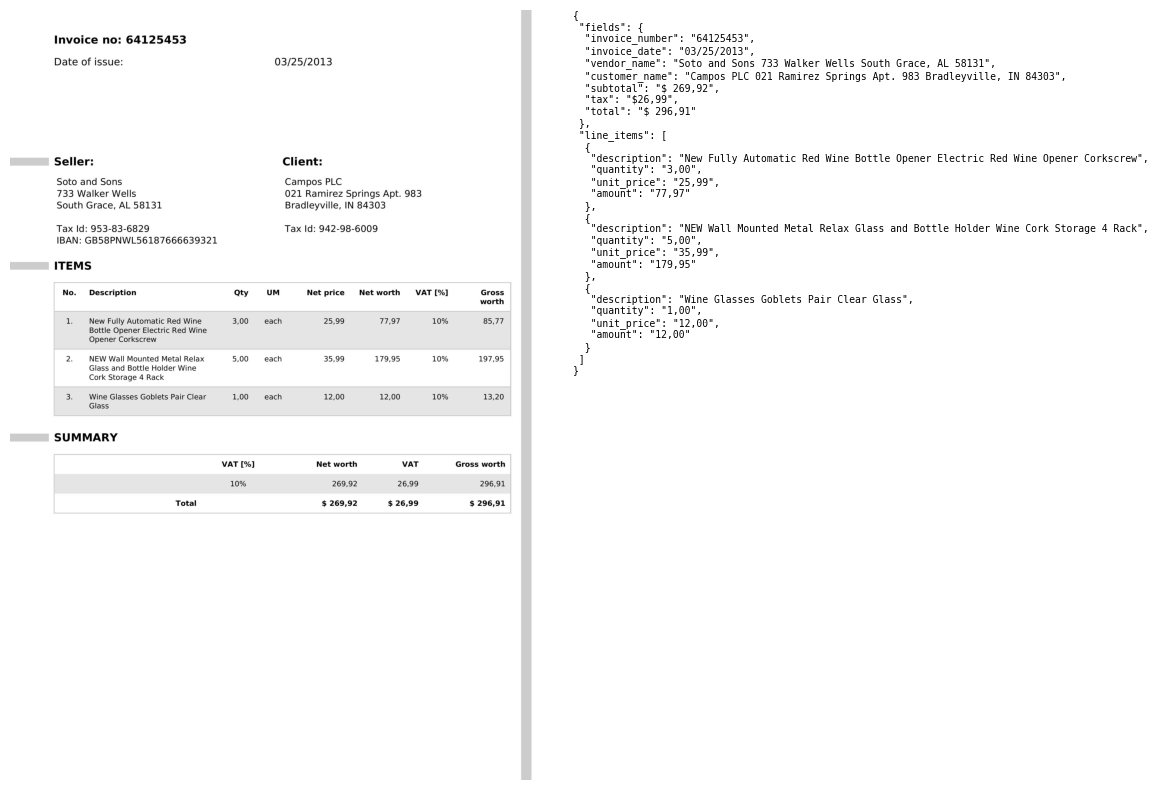

In [5]:
# Held-out set with ground truth: synthetic invoices with labelled header fields and line items.
# To use your own invoices, set LOCAL_DOCS_DIR (see the markdown above).
LOCAL_DOCS_DIR = None

def gt_to_schema(gt):
    h, s, items = gt.get("header", {}), gt.get("summary", {}), gt.get("items", [])
    return {"fields": {"invoice_number": h.get("invoice_no"), "invoice_date": h.get("invoice_date"),
                       "vendor_name": h.get("seller"), "customer_name": h.get("client"),
                       "subtotal": s.get("total_net_worth"), "tax": s.get("total_vat"), "total": s.get("total_gross_worth")},
            "line_items": [{"description": it.get("item_desc"), "quantity": it.get("item_qty"),
                            "unit_price": it.get("item_net_price"), "amount": it.get("item_net_worth")} for it in items]}

def build_docs_local(folder):
    folder = Path(folder)
    labels = json.loads((folder / "labels.json").read_text())      # {"file.png": {"fields": {...}, "line_items": [...]}}
    docs = []
    for i, (fname, gt) in enumerate(labels.items()):
        gt.setdefault("fields", {}); gt.setdefault("line_items", [])
        docs.append(dict(doc_id=f"L{i:03d}", image=Image.open(folder / fname).convert("RGB"), gt=gt))
    return docs

if LOCAL_DOCS_DIR:
    all_docs = build_docs_local(LOCAL_DOCS_DIR)
    dev_docs, test_docs = all_docs[:max(3, len(all_docs) // 3)], all_docs[max(3, len(all_docs) // 3):][:N_TEST]
else:
    from datasets import load_dataset
    dsd = load_dataset("katanaml-org/invoices-donut-data-v1")
    print("splits:", {k: len(v) for k, v in dsd.items()})
    dev_split = "validation" if "validation" in dsd else "train"

    def build_docs(split, n, prefix):
        rows = dsd[split].shuffle(seed=SEED).select(range(min(n, len(dsd[split]))))
        docs = []
        for i, r in enumerate(rows):
            gt = json.loads(r["ground_truth"]); gt = gt.get("gt_parse", gt)
            docs.append(dict(doc_id=f"{prefix}{i:03d}", image=r["image"].convert("RGB"), gt=gt_to_schema(gt)))
        return docs

    dev_docs = build_docs(dev_split, 10, "d")      # DEV: tune rules and settings on these
    test_docs = build_docs("test", N_TEST, "t")    # HELD-OUT: only used for the final comparison

print(f"dev docs: {len(dev_docs)} | held-out test docs: {len(test_docs)}")

d0 = dev_docs[0]
fig, ax = plt.subplots(1, 2, figsize=(13, 8), gridspec_kw={"width_ratios": [1.1, 1]})
ax[0].imshow(d0["image"]); ax[0].axis("off")
ax[1].axis("off"); ax[1].text(0, 1, json.dumps(d0["gt"], indent=1)[:1800], va="top", family="monospace", fontsize=7)
plt.tight_layout(); plt.show()

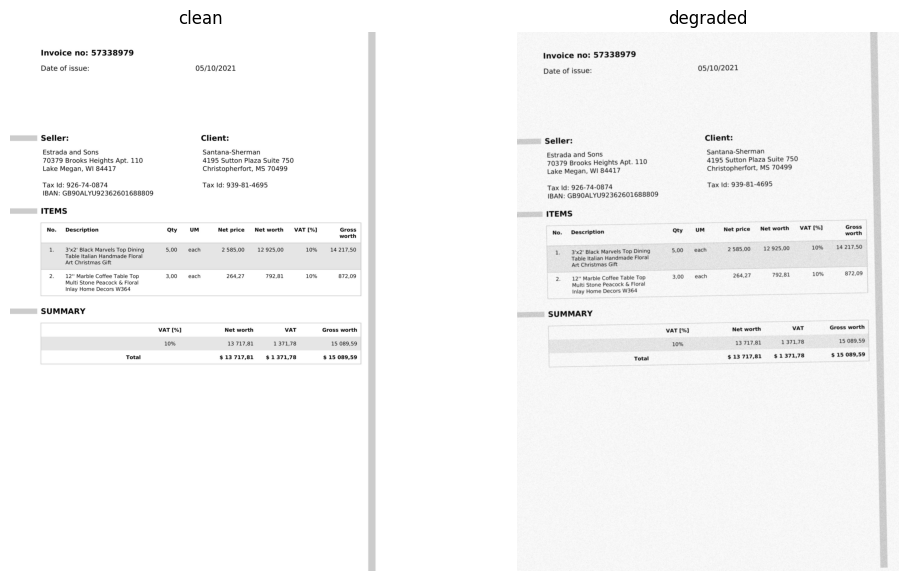

In [6]:
def degrade(img, seed):
    # make a clean invoice look like a poor scan: small rotation, blur, noise and heavy JPEG compression
    rng = np.random.default_rng(seed)
    a = np.array(img.convert("L"))
    H, W = a.shape
    M = cv2.getRotationMatrix2D((W / 2, H / 2), float(rng.uniform(-4, 4)), 1.0)
    a = cv2.warpAffine(a, M, (W, H), borderMode=cv2.BORDER_CONSTANT, borderValue=255)
    a = cv2.GaussianBlur(a, (0, 0), 1.2)
    a = np.clip(a.astype(np.float32) + rng.normal(0, 18, a.shape), 0, 255).astype(np.uint8)
    ok, enc = cv2.imencode(".jpg", a, [cv2.IMWRITE_JPEG_QUALITY, 35])
    return Image.fromarray(cv2.imdecode(enc, cv2.IMREAD_GRAYSCALE)).convert("RGB")

hard_docs = [dict(doc_id=f"h{i:03d}", image=degrade(d["image"], i), gt=d["gt"]) for i, d in enumerate(test_docs[:N_HARD])]

fig, ax = plt.subplots(1, 2, figsize=(12, 7))
ax[0].imshow(test_docs[0]["image"]); ax[0].set_title("clean"); ax[1].imshow(hard_docs[0]["image"]); ax[1].set_title("degraded")
for a in ax: a.axis("off")
plt.show()

## 6. Day 1: The OCR landscape and preprocessing

- **Tesseract:** the classic open-source engine, fast and CPU-only, good on clean printed text, sensitive to skew and noise.
- **EasyOCR:** deep-learning text detector and recognizer (PyTorch), better on messy images, slower, benefits from a GPU.
- **PaddleOCR:** another strong open-source option (not run here).

Preprocessing steps: **denoise**, **deskew** (rotate so text lines are horizontal), **threshold** (turn the page into black text on white). The comparison below uses *token recall*: the share of ground-truth words and numbers that appear in the OCR text. It is a quick proxy, not a full character-error-rate measurement.

In [7]:
BEST_PRE = "none"     # preprocessing mode used by the pipeline; chosen from the Day 1 comparison

def deskew(g, max_angle=5, step=0.5):
    # try small rotations and keep the one that makes text rows line up best (sharpest row profile)
    small = cv2.resize(g, None, fx=0.25, fy=0.25) if max(g.shape) > 1000 else g
    bw = (small < 128).astype(np.uint8)
    h, w = bw.shape
    best, best_score = 0.0, -1.0
    for a in np.arange(-max_angle, max_angle + 1e-9, step):
        M = cv2.getRotationMatrix2D((w / 2, h / 2), a, 1.0)
        r = cv2.warpAffine(bw, M, (w, h), flags=cv2.INTER_NEAREST)
        score = float(np.var(r.sum(axis=1)))
        if score > best_score: best, best_score = a, score
    if abs(best) < 0.2: return g
    H, W = g.shape
    M = cv2.getRotationMatrix2D((W / 2, H / 2), best, 1.0)
    return cv2.warpAffine(g, M, (W, H), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

def preprocess(img, mode="none"):
    g = cv2.cvtColor(np.array(img.convert("RGB")), cv2.COLOR_RGB2GRAY)
    if mode == "none": return Image.fromarray(g)
    scale = 2000 / max(g.shape)
    if scale > 1.05: g = cv2.resize(g, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    g = cv2.fastNlMeansDenoising(g, h=10)
    g = deskew(g)
    bw = cv2.adaptiveThreshold(g, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 31, 15)
    return Image.fromarray(bw)

In [8]:
def tess_words(img, psm=6):
    d = pytesseract.image_to_data(img, config=f"--oem 3 --psm {psm}", output_type=pytesseract.Output.DICT)
    words = []
    for i, t in enumerate(d["text"]):
        t = str(t).strip()
        if not t or float(d["conf"][i]) < 0: continue
        words.append(dict(text=t, x=int(d["left"][i]), y=int(d["top"][i]), w=int(d["width"][i]), h=int(d["height"][i]),
                          conf=float(d["conf"][i]), line=(d["block_num"][i], d["par_num"][i], d["line_num"][i])))
    return words

def ocr_lines(words):
    groups = {}
    for w in words: groups.setdefault(w["line"], []).append(w)
    out = []
    for ws in groups.values():
        ws.sort(key=lambda w: w["x"])
        out.append(dict(words=ws, text=" ".join(w["text"] for w in ws),
                        y=float(np.mean([w["y"] + w["h"] / 2 for w in ws])),
                        x0=min(w["x"] for w in ws), x1=max(w["x"] + w["w"] for w in ws)))
    out.sort(key=lambda l: l["y"])
    return out

def tess_text(img, psm=6):
    return "\n".join(l["text"] for l in ocr_lines(tess_words(img, psm)))

def tokens(s): return re.findall(r"[a-z0-9]+", str(s).lower())

def gt_tokens(gt):
    toks = []
    for v in gt["fields"].values():
        if v: toks += tokens(v)
    for it in gt["line_items"]:
        for k in ITEM_KEYS:
            if it.get(k) not in (None, ""): toks += tokens(it[k])
    return toks

def token_recall(text, gt):
    have, g = set(tokens(text)), gt_tokens(gt)
    return sum(t in have for t in g) / max(len(g), 1)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


,OCR method,token recall (clean),token recall (degraded),sec / page (clean)
0,Tesseract (grayscale),0.990,0.995,4.2
1,Tesseract (denoise + deskew + threshold),0.986,0.993,27.2
2,EasyOCR,0.988,0.985,92.2


Preprocessing mode chosen for the pipeline: none


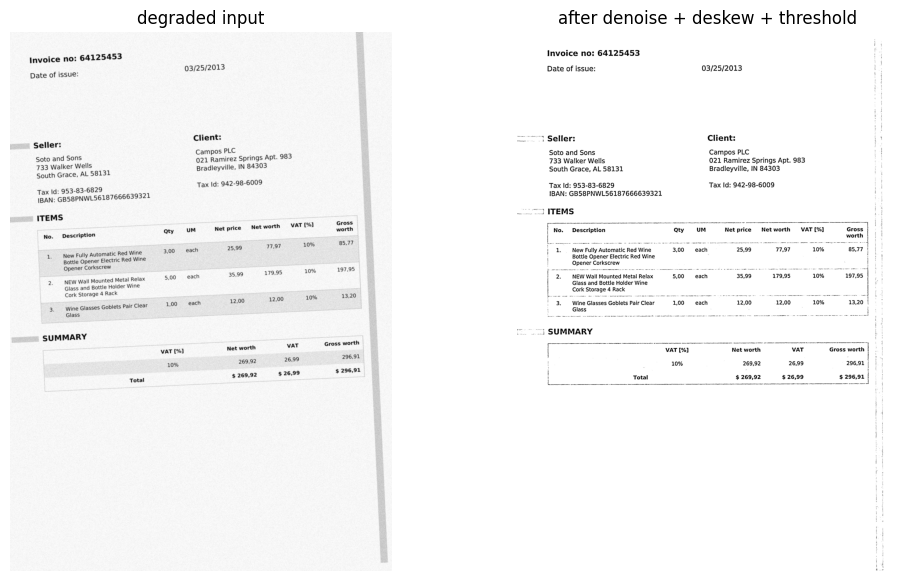

In [9]:
import easyocr
reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)

def ocr_text(method, img):
    if method == "Tesseract (grayscale)": return tess_text(preprocess(img, "none"))
    if method == "Tesseract (denoise + deskew + threshold)": return tess_text(preprocess(img, "pre"))
    if method == "EasyOCR": return "\n".join(reader.readtext(np.array(img.convert("RGB")), detail=0, paragraph=False))

sample_clean = dev_docs[:6]
sample_hard = [dict(doc_id=d["doc_id"], image=degrade(d["image"], 100 + i), gt=d["gt"]) for i, d in enumerate(sample_clean)]
rows = []
for method in ["Tesseract (grayscale)", "Tesseract (denoise + deskew + threshold)", "EasyOCR"]:
    t0 = time.time(); clean = np.mean([token_recall(ocr_text(method, d["image"]), d["gt"]) for d in sample_clean]); t_clean = (time.time() - t0) / len(sample_clean)
    hard = np.mean([token_recall(ocr_text(method, d["image"]), d["gt"]) for d in sample_hard])
    rows.append({"OCR method": method, "token recall (clean)": round(clean, 3), "token recall (degraded)": round(hard, 3), "sec / page (clean)": round(t_clean, 1)})
ocr_df = pd.DataFrame(rows); display(ocr_df)

r = {row["OCR method"]: row for row in rows}
BEST_PRE = "pre" if (r["Tesseract (denoise + deskew + threshold)"]["token recall (clean)"] + r["Tesseract (denoise + deskew + threshold)"]["token recall (degraded)"]
                     > r["Tesseract (grayscale)"]["token recall (clean)"] + r["Tesseract (grayscale)"]["token recall (degraded)"]) else "none"
print("Preprocessing mode chosen for the pipeline:", BEST_PRE)

fig, ax = plt.subplots(1, 2, figsize=(12, 7))
ax[0].imshow(sample_hard[0]["image"]); ax[0].set_title("degraded input")
ax[1].imshow(preprocess(sample_hard[0]["image"], "pre"), cmap="gray"); ax[1].set_title("after denoise + deskew + threshold")
for a in ax: a.axis("off")
plt.show()

## 7. Day 2: Layout-aware extraction (self-hosted)

Plain OCR gives a bag of words. **Layout** (where each word sits on the page) is what turns it into fields and tables: a number under the "Net worth" header is an amount, a name to the right of "Client:" is the customer. The self-hosted pipeline here uses Tesseract word boxes and rules:

1. Group words into text lines, using their positions.
2. **Key-value fields:** regular expressions on labelled lines (`Invoice no:`, `Date of issue:`, `Total`), and a position split for the two-column Seller/Client block.
3. **Table:** find the header row, turn its words into column cells, put the words of each row into the column they fall under, merge wrapped lines.

This is a deliberate, transparent baseline. Learned layout models (LayoutLMv3, Donut) read layout inside the network instead, but they need fine-tuning data for invoices.

In [11]:
DATE_PAT = r"(\d{1,2}[/.\-]\d{1,2}[/.\-]\d{2,4}|\d{4}[/.\-]\d{1,2}[/.\-]\d{1,2}|[A-Za-z]{3,9}\.?\s+\d{1,2},?\s+\d{4}|\d{1,2}\s+[A-Za-z]{3,9}\.?,?\s+\d{4})"
MONEY = re.compile(r"\d{1,3}(?:[ .,]\d{3})*[.,]\d{2}(?!\d)")

def amounts_in(text):
    vals = [to_number(m.group(0)) for m in MONEY.finditer(text)]
    return [v for v in vals if v is not None]

def extract_parties(lines):
    # 1) two-column "Seller: ... Client: ..." header, split by x position
    hdr = next((i for i, l in enumerate(lines) if re.search(r"\bseller\b", l["text"], re.I) and re.search(r"\bclient\b", l["text"], re.I)), None)
    if hdr is not None:
        ws = lines[hdr]["words"]
        cx = next(w["x"] for w in ws if w["text"].lower().startswith("client"))
        left, right = [], []
        for l in lines[hdr + 1:]:
            if re.search(r"tax\s*id|iban|^items", l["text"], re.I): break
            lw = " ".join(w["text"] for w in l["words"] if w["x"] < cx - 10)
            rw = " ".join(w["text"] for w in l["words"] if w["x"] >= cx - 10)
            if lw: left.append(lw)
            if rw: right.append(rw)
        if left or right: return " ".join(left) or None, " ".join(right) or None
    # 2) labelled lines ("Bill to: ...", "Vendor: ...")
    def after_label(pat):
        for i, l in enumerate(lines):
            m = re.search(pat + r"\s*[:\-]?\s*(.*)$", l["text"], re.I)
            if m:
                rest = m.group(1).strip()
                if len(rest) > 2: return rest
                if i + 1 < len(lines): return lines[i + 1]["text"].strip()
        return None
    vendor = after_label(r"\b(?:seller|vendor|supplier|from)\b")
    customer = after_label(r"\b(?:bill\s*to|client|customer|buyer)\b")
    if vendor is None:   # 3) fallback: first line with letters that is not the word "invoice"
        vendor = next((l["text"] for l in lines if re.search(r"[A-Za-z]{3,}", l["text"]) and not re.search(r"invoice", l["text"], re.I)), None)
    return vendor, customer

def extract_fields(lines):
    f = {k: None for k in FIELDS}
    full = "\n".join(l["text"] for l in lines)
    for pat in [r"invoice\s*(?:no|number|num|nr|#)\.?\s*[:#.]?\s*([A-Za-z0-9][A-Za-z0-9\-/]{2,})", r"\binv\s*#?\s*[:.]?\s*([A-Za-z0-9\-]{4,})"]:
        m = re.search(pat, full, re.I)
        if m: f["invoice_number"] = m.group(1); break
    for pat in [r"date\s*of\s*issue\s*[:\-]?\s*" + DATE_PAT, r"invoice\s*date\s*[:\-]?\s*" + DATE_PAT, r"\bdate\s*[:\-]?\s*" + DATE_PAT, DATE_PAT]:
        m = re.search(pat, full, re.I)
        if m: f["invoice_date"] = m.group(1); break
    tot = [i for i, l in enumerate(lines) if re.search(r"\btotal\b", l["text"], re.I) and amounts_in(l["text"])]
    if tot:
        a = amounts_in(lines[tot[-1]]["text"])
        if len(a) >= 3: f["subtotal"], f["tax"], f["total"] = a[-3], a[-2], a[-1]
        else: f["total"] = a[-1]
    for key, pat in [("subtotal", r"sub\s*-?\s*total|net\s*worth"), ("tax", r"\b(?:tax|vat)\b")]:
        if f[key] is None:
            for l in lines:
                if re.search(pat, l["text"], re.I) and amounts_in(l["text"]):
                    f[key] = amounts_in(l["text"])[-1]; break
    f["vendor_name"], f["customer_name"] = extract_parties(lines)
    return f

HEADER_VOCAB = ["description", "quantity", "qty", "price", "worth", "amount", "total", "net", "gross", "unit", "item", "vat", "no"]
START_WORDS = {"net", "gross", "vat", "unit", "qty", "quantity", "description", "no", "um", "amount", "total", "tax", "rate", "item", "product", "details"}

def fix_word(t):
    # tolerate small OCR errors in header words ("wotr" -> "worth")
    t0 = re.sub(r"[^a-z]", "", t.lower())
    if not t0: return t.lower()
    m = difflib.get_close_matches(t0, HEADER_VOCAB, n=1, cutoff=0.55)
    return m[0] if m else t0

def header_key(text):
    t = " ".join(fix_word(w) for w in text.split())
    if re.fullmatch(r"no|#", t): return "index"
    if re.search(r"descr|item|product|details", t): return "description"
    if re.search(r"qty|quant", t): return "quantity"
    if re.search(r"net price|unit price|price|rate", t) and "gross" not in t: return "unit_price"
    if re.search(r"net worth|amount|line total|^total", t) and "gross" not in t: return "amount"
    return None

def first_number(s):
    m = re.search(r"\d{1,3}(?:[ .,]\d{3})+(?:[.,]\d{1,2})?|\d+(?:[.,]\d+)?", str(s or ""))
    return to_number(m.group(0)) if m else None

def find_table(lines):
    h = next((i for i, l in enumerate(lines) if re.search(r"descr|item\b|product", l["text"], re.I)
              and re.search(r"qty|quant|price|amount|worth", l["text"], re.I)), None)
    if h is None: return None
    ws = sorted(lines[h]["words"], key=lambda w: w["x"])
    gap = 1.2 * float(np.median([w["h"] for w in ws]))
    groups, cur = [], [ws[0]]
    def starts_new(w, prev):
        t, p = fix_word(w["text"]), fix_word(prev["text"])
        if t in ("price", "worth", "amount") and p in ("net", "gross", "unit", "total", "line"): return False
        return t in START_WORDS or t in ("price", "worth")
    for w in ws[1:]:
        if w["x"] - (cur[-1]["x"] + cur[-1]["w"]) > gap or starts_new(w, cur[-1]): groups.append(cur); cur = [w]
        else: cur.append(w)
    groups.append(cur)
    cells = [dict(text=" ".join(w["text"] for w in g), x0=g[0]["x"], x1=g[-1]["x"] + g[-1]["w"]) for g in groups]
    bounds = [(cells[i]["x1"] + cells[i + 1]["x0"]) / 2 for i in range(len(cells) - 1)]
    stop = len(lines)
    for j in range(h + 1, len(lines)):
        if re.search(r"^\s*summary\b|\bsubtotal\b|^\s*total\b", lines[j]["text"], re.I): stop = j; break
    return dict(h=h, cells=cells, bounds=bounds, stop=stop)

def extract_table(lines):
    t = find_table(lines)
    if t is None: return []
    keys = [header_key(c["text"]) for c in t["cells"]]
    rows = []
    for l in lines[t["h"] + 1: t["stop"]]:
        cells = {}
        for w in l["words"]:
            k = keys[sum((w["x"] + w["w"] / 2) > b for b in t["bounds"])]
            if k: cells[k] = (cells.get(k, "") + " " + w["text"]).strip()
        if not cells: continue
        starts = (re.fullmatch(r"\d{1,3}\.?", cells.get("index", "")) is not None) if "index" in keys else True
        if starts or not rows:
            rows.append(cells)
        else:                                   # continuation line of the previous row (wrapped description)
            if "description" in cells:
                rows[-1]["description"] = (rows[-1].get("description", "") + " " + cells["description"]).strip()
            for k in ("quantity", "unit_price", "amount"):
                if k in cells and k not in rows[-1]: rows[-1][k] = cells[k]
    return [dict(description=r.get("description"), quantity=first_number(r.get("quantity")),
                 unit_price=first_number(r.get("unit_price")), amount=first_number(r.get("amount"))) for r in rows]

def selfhosted_extract(doc):
    t0 = time.time()
    words = tess_words(preprocess(doc["image"], BEST_PRE), psm=6)
    lines = ocr_lines(words)
    out = empty_doc(doc["doc_id"], "tesseract+layout-rules")
    out["fields"].update(extract_fields(lines))
    out["line_items"] = extract_table(lines)
    out["meta"] = dict(latency_s=time.time() - t0, pages=1, n_words=len(words))
    return out

In [ ]:
def show_layout(doc, psm=6, mode=None):
    img = preprocess(doc["image"], mode or BEST_PRE)
    words = tess_words(img, psm); lines = ocr_lines(words); t = find_table(lines)
    vis = np.array(img.convert("RGB"))
    for w in words:
        c = (0, 160, 0) if w["conf"] > 80 else (255, 140, 0) if w["conf"] > 50 else (220, 0, 0)
        cv2.rectangle(vis, (w["x"], w["y"]), (w["x"] + w["w"], w["y"] + w["h"]), c, 1)
    if t:
        y0, y1 = int(lines[t["h"]]["y"] - 25), int(lines[max(t["stop"] - 1, t["h"])]["y"] + 25)
        for b in t["bounds"]: cv2.line(vis, (int(b), y0), (int(b), y1), (0, 0, 255), 2)
    plt.figure(figsize=(10, 13)); plt.imshow(vis); plt.axis("off"); plt.title("word boxes (green = confident) and detected table columns (blue)"); plt.show()
    return lines

lines = show_layout(dev_docs[0])
print("\n".join(l["text"] for l in lines[:25]))

In [10]:
doc = dev_docs[0]
out = selfhosted_extract(doc)
print("valid against schema:", is_valid(out), "| latency", round(out["meta"]["latency_s"], 1), "s")
print(json.dumps({k: out[k] for k in ["fields", "line_items"]}, indent=1)[:2500])
print("\nGROUND TRUTH fields:", json.dumps(doc["gt"]["fields"], indent=1))

NameError: name 'selfhosted_extract' is not defined

### Optional: Donut (OCR-free document understanding)

Donut reads the page image directly and writes JSON, with no OCR step. The checkpoint below was fine-tuned on **receipts** (CORD), not invoices, so treat it as a demo of the idea, not as a third system in the comparison. Run it on a GPU.

In [ ]:
from transformers import DonutProcessor, VisionEncoderDecoderModel

name = "naver-clova-ix/donut-base-finetuned-cord-v2"           # trained on RECEIPTS (CORD), not invoices
processor = DonutProcessor.from_pretrained(name)
donut = VisionEncoderDecoderModel.from_pretrained(name).to(dev).eval()

def donut_parse(img):
    pixel_values = processor(img.convert("RGB"), return_tensors="pt").pixel_values.to(dev)
    prompt_ids = processor.tokenizer("<s_cord-v2>", add_special_tokens=False, return_tensors="pt").input_ids.to(dev)
    with torch.no_grad():
        out = donut.generate(pixel_values, decoder_input_ids=prompt_ids,
                             max_length=donut.decoder.config.max_position_embeddings,
                             pad_token_id=processor.tokenizer.pad_token_id, eos_token_id=processor.tokenizer.eos_token_id,
                             use_cache=True, bad_words_ids=[[processor.tokenizer.unk_token_id]], return_dict_in_generate=True)
    seq = processor.batch_decode(out.sequences)[0]
    seq = seq.replace(processor.tokenizer.eos_token, "").replace(processor.tokenizer.pad_token, "")
    seq = re.sub(r"<.*?>", "", seq, count=1).strip()
    return processor.token2json(seq)

t0 = time.time()
parsed = donut_parse(dev_docs[0]["image"])
print(f"{time.time() - t0:.1f} s")
print(json.dumps(parsed, indent=1)[:1500])

## 8. Day 3: Managed services

Both services take an image and return structured fields and tables. **Azure `prebuilt-invoice`** and **AWS Textract `AnalyzeExpense`** are pretrained for invoices and receipts. (AWS also offers `AnalyzeDocument` with forms and tables, and Google Document AI is a third option; they are not run here.) The adapters below convert each response to the common schema.

Before running the cell: add your secrets (section 2). It sends **one** page as a smoke test, then every later result is cached in `/content/cloud_cache`.

In [12]:
CLOUD_PAGES = {s: len(list((CACHE / s).glob("*.json"))) if (CACHE / s).exists() else 0 for s in ["azure", "textract"]}

def have_creds(service):
    if service == "azure": return bool(secret("AZURE_DI_ENDPOINT") and secret("AZURE_DI_KEY"))
    return bool(secret("AWS_ACCESS_KEY_ID") and secret("AWS_SECRET_ACCESS_KEY"))

def png_bytes(img):
    buf = io.BytesIO(); img.convert("RGB").save(buf, format="PNG"); return buf.getvalue()

# ---------- Azure AI Document Intelligence (prebuilt-invoice) ----------
def azure_analyze(img):
    from azure.ai.documentintelligence import DocumentIntelligenceClient
    from azure.core.credentials import AzureKeyCredential
    client = DocumentIntelligenceClient(endpoint=secret("AZURE_DI_ENDPOINT"), credential=AzureKeyCredential(secret("AZURE_DI_KEY")))
    t0 = time.time()
    result = client.begin_analyze_document("prebuilt-invoice", body=io.BytesIO(png_bytes(img))).result()
    return result, time.time() - t0

def azure_to_schema(doc_id, result):
    out = empty_doc(doc_id, "azure-document-intelligence/prebuilt-invoice")
    if not result.documents: return out
    f = result.documents[0].fields or {}
    def val(x):
        if x is None: return None
        if getattr(x, "value_currency", None) is not None: return x.value_currency.amount
        if getattr(x, "value_date", None) is not None: return str(x.value_date)
        if getattr(x, "value_number", None) is not None: return x.value_number
        return getattr(x, "value_string", None) or x.content
    for k, name in [("invoice_number", "InvoiceId"), ("invoice_date", "InvoiceDate"), ("vendor_name", "VendorName"),
                    ("customer_name", "CustomerName"), ("subtotal", "SubTotal"), ("tax", "TotalTax"), ("total", "InvoiceTotal")]:
        out["fields"][k] = val(f.get(name))
    items = f.get("Items")
    for it in (items.value_array if items is not None and items.value_array else []):
        o = it.value_object or {}
        out["line_items"].append({"description": val(o.get("Description")), "quantity": val(o.get("Quantity")),
                                  "unit_price": val(o.get("UnitPrice")), "amount": val(o.get("Amount"))})
    return out

# ---------- AWS Textract (AnalyzeExpense) ----------
def textract_analyze(img):
    import boto3
    client = boto3.client("textract", region_name=secret("AWS_REGION") or "us-east-1",
                          aws_access_key_id=secret("AWS_ACCESS_KEY_ID"), aws_secret_access_key=secret("AWS_SECRET_ACCESS_KEY"))
    t0 = time.time()
    resp = client.analyze_expense(Document={"Bytes": png_bytes(img)})
    return resp, time.time() - t0

def textract_to_schema(doc_id, resp):
    out = empty_doc(doc_id, "aws-textract/analyze-expense")
    docs = resp.get("ExpenseDocuments", [])
    if not docs: return out
    summ = {}
    for fld in docs[0].get("SummaryFields", []):
        t, v = fld.get("Type", {}).get("Text"), fld.get("ValueDetection", {}).get("Text")
        if t and v and t not in summ: summ[t] = v
    mapping = {"invoice_number": "INVOICE_RECEIPT_ID", "invoice_date": "INVOICE_RECEIPT_DATE", "vendor_name": "VENDOR_NAME",
               "customer_name": "RECEIVER_NAME", "subtotal": "SUBTOTAL", "tax": "TAX", "total": "TOTAL"}
    for k, t in mapping.items(): out["fields"][k] = summ.get(t)
    out["fields"]["total"] = out["fields"]["total"] or summ.get("AMOUNT_DUE")
    out["fields"]["customer_name"] = out["fields"]["customer_name"] or summ.get("RECEIVER_BILL_TO")
    for grp in docs[0].get("LineItemGroups", []):
        for li in grp.get("LineItems", []):
            row = {}
            for fld in li.get("LineItemExpenseFields", []):
                row[fld.get("Type", {}).get("Text")] = fld.get("ValueDetection", {}).get("Text")
            out["line_items"].append({"description": row.get("ITEM"), "quantity": to_number(row.get("QUANTITY")),
                                      "unit_price": to_number(row.get("UNIT_PRICE")), "amount": to_number(row.get("PRICE"))})
    return out

def managed_extract(service, doc):
    d = CACHE / service; d.mkdir(parents=True, exist_ok=True)
    p = d / f"{doc['doc_id']}.json"
    if p.exists(): return json.loads(p.read_text())                  # cached: no new page is sent or charged
    if CLOUD_PAGES[service] >= MAX_CLOUD_PAGES:
        raise RuntimeError(f"page cap reached for {service} ({MAX_CLOUD_PAGES}); raise MAX_CLOUD_PAGES on purpose if you want more")
    if service == "azure": res, lat = azure_analyze(doc["image"]); out = azure_to_schema(doc["doc_id"], res)
    else: res, lat = textract_analyze(doc["image"]); out = textract_to_schema(doc["doc_id"], res)
    out["meta"] = dict(latency_s=lat, pages=1)
    p.write_text(json.dumps(out, default=str)); CLOUD_PAGES[service] += 1
    return out

AVAILABLE = [s for s in MANAGED_SERVICES if have_creds(s)]
print("managed services with credentials:", AVAILABLE or "NONE (add secrets, see the markdown above)")
if AVAILABLE:
    s = AVAILABLE[0]
    o = managed_extract(s, dev_docs[0])        # sends ONE page
    print(s, "| latency", round(o["meta"]["latency_s"], 1), "s | valid:", is_valid(o))
    print(json.dumps({k: o[k] for k in ["fields", "line_items"]}, indent=1)[:2000])
    print("pages sent so far:", CLOUD_PAGES)

managed services with credentials: NONE (add secrets, see the markdown above)


## 9. Day 4: Hard cases and tuning on the dev set

Push the self-hosted pipeline on the cases it gets wrong: merged or wrapped cells, long descriptions, multi-line addresses, rotated or noisy scans. **Tune only on the dev documents**, and run the managed service on the held-out set only once (it costs money). Change the rules in section 7 (`extract_fields`, `find_table`, `extract_table`), re-run, and watch the dev score. When you are happy, stop and freeze the code before the held-out run.

In [13]:
def run_system(extract_fn, docs, source):
    outs = []
    for d in docs:
        try: o = extract_fn(d)
        except Exception as e:
            o = empty_doc(d["doc_id"], source); o["meta"] = dict(error=str(e)[:200], latency_s=None)
        outs.append(o)
    return outs

def evaluate(outs, docs):
    ok = {k: [] for k in FIELDS}; nonempty = []
    tp = gt_c = pr_c = r_gt = r_pr = r_m = 0
    for o, d in zip(outs, docs):
        for k in FIELDS:
            m = match_field(k, o["fields"].get(k), d["gt"]["fields"].get(k))
            if m is not None:
                ok[k].append(m); nonempty.append(o["fields"].get(k) not in (None, ""))
        s = table_scores(o["line_items"], d["gt"]["line_items"])
        tp += s["tp"]; gt_c += s["gt_cells"]; pr_c += s["pred_cells"]; r_gt += s["rows_gt"]; r_pr += s["rows_pred"]; r_m += s["rows_matched"]
    per_field = {k: (float(np.mean(v)) if v else float("nan")) for k, v in ok.items()}
    p, r = tp / max(pr_c, 1), tp / max(gt_c, 1)
    lat = [o["meta"].get("latency_s") for o in outs if o["meta"].get("latency_s") is not None]
    return dict(valid=float(np.mean([is_valid(o) for o in outs])), per_field=per_field,
                field_acc=float(np.nanmean(list(per_field.values()))),
                cell_p=p, cell_r=r, cell_f1=(2 * p * r / (p + r) if p + r else 0.0),
                row_recall=r_m / max(r_gt, 1), row_precision=r_m / max(r_pr, 1),
                latency_median=float(np.median(lat)) if lat else float("nan"),
                errors=sum(1 for o in outs if "error" in o["meta"]))

In [14]:
def fail_report(outs, docs, label, n=3):
    scored = []
    for o, d in zip(outs, docs):
        res = [match_field(k, o["fields"].get(k), d["gt"]["fields"].get(k)) for k in FIELDS]
        scored.append((sum(1 for r in res if r is False), o, d))
    print(f"##### {label}")
    for nbad, o, d in sorted(scored, key=lambda x: -x[0])[:n]:
        print(f"--- {d['doc_id']} | {nbad} wrong fields | rows predicted {len(o['line_items'])} vs {len(d['gt']['line_items'])} true")
        for k in FIELDS:
            if match_field(k, o["fields"].get(k), d["gt"]["fields"].get(k)) is False:
                print(f"   {k:15s} predicted: {str(o['fields'].get(k))[:60]!r:64s} truth: {str(d['gt']['fields'].get(k))[:60]!r}")

In [15]:
dev_outs = run_system(selfhosted_extract, dev_docs, "self")
dev_score = evaluate(dev_outs, dev_docs)
print("DEV set, self-hosted pipeline (free to run, so iterate here):")
print({k: round(v, 3) for k, v in dev_score.items() if k not in ("per_field", "errors")})
print({k: round(v, 2) for k, v in dev_score["per_field"].items()})
fail_report(dev_outs, dev_docs, "worst DEV documents", n=3)

DEV set, self-hosted pipeline (free to run, so iterate here):
{'valid': 1.0, 'field_acc': 1.0, 'cell_p': 0.927, 'cell_r': 0.795, 'cell_f1': 0.856, 'row_recall': 0.857, 'row_precision': 1.0, 'latency_median': 4.388}
{'invoice_number': 1.0, 'invoice_date': 1.0, 'vendor_name': 1.0, 'customer_name': 1.0, 'subtotal': 1.0, 'tax': 1.0, 'total': 1.0}
##### worst DEV documents
--- d000 | 0 wrong fields | rows predicted 2 vs 3 true
--- d001 | 0 wrong fields | rows predicted 2 vs 2 true
--- d002 | 0 wrong fields | rows predicted 2 vs 2 true


## 10. Day 5: The held-out evaluation

Every system runs on the same held-out invoices, clean and degraded. This sends up to `N_TEST + N_HARD` pages to each managed service (the result is cached, so re-running is free).

In [16]:
SYSTEMS = {"Self-hosted (Tesseract + layout rules)": ("self", selfhosted_extract)}
for s in AVAILABLE:
    SYSTEMS[{"azure": "Azure Document Intelligence", "textract": "AWS Textract"}[s]] = (s, (lambda d, s=s: managed_extract(s, d)))

OUTS = {}      # (system, condition) -> outputs
SCORES = {}    # (system, condition) -> metrics
for name, (kind, fn) in SYSTEMS.items():
    for cond, docs in [("clean", test_docs), ("degraded", hard_docs)]:
        print(f"running {name} on {cond} ({len(docs)} docs)...")
        OUTS[(name, cond)] = run_system(fn, docs, name)
        SCORES[(name, cond)] = evaluate(OUTS[(name, cond)], docs)
print("done | cloud pages sent:", CLOUD_PAGES)

running Self-hosted (Tesseract + layout rules) on clean (20 docs)...
running Self-hosted (Tesseract + layout rules) on degraded (8 docs)...
done | cloud pages sent: {'azure': 0, 'textract': 0}


### Comparison matrix

In [17]:
def cost_per_1000(name, kind):
    if kind == "self":
        lat = SCORES[(name, "clean")]["latency_median"]
        return SELF_HOSTED_USD_PER_HOUR * lat / 3600 * 1000
    return PRICE_PER_PAGE[kind] * 1000

rows = []
for name, (kind, _) in SYSTEMS.items():
    c, h = SCORES[(name, "clean")], SCORES[(name, "degraded")]
    rows.append({"System": name,
                 "Valid JSON": f"{c['valid']*100:.0f}%",
                 "Field accuracy (clean)": round(c["field_acc"], 3),
                 "Field accuracy (degraded)": round(h["field_acc"], 3),
                 "Table cell F1 (clean)": round(c["cell_f1"], 3),
                 "Table cell F1 (degraded)": round(h["cell_f1"], 3),
                 "Table row recall (clean)": round(c["row_recall"], 3),
                 "Median latency (s/page)": round(c["latency_median"], 1),
                 "Cost per 1,000 pages (USD)": round(cost_per_1000(name, kind), 2),
                 "Data leaves your machine": "no" if kind == "self" else "yes"})
matrix = pd.DataFrame(rows).set_index("System").T
display(matrix)

print("Per-field accuracy (clean held-out set):")
display(pd.DataFrame({name: SCORES[(name, "clean")]["per_field"] for name in SYSTEMS}).round(3))

md = "| Criterion | " + " | ".join(matrix.columns) + " |\n|---|" + "---|" * len(matrix.columns) + "\n"
for idx, row in matrix.iterrows(): md += f"| {idx} | " + " | ".join(str(v) for v in row.values) + " |\n"
print("\nCopy into your README:\n"); print(md)

System,Self-hosted (Tesseract + layout rules)
Valid JSON,100%
Field accuracy (clean),0.964
Field accuracy (degraded),0.982
Table cell F1 (clean),0.872
Table cell F1 (degraded),0.705
Table row recall (clean),0.867
Median latency (s/page),3.5
"Cost per 1,000 pages (USD)",0.1
Data leaves your machine,no


Per-field accuracy (clean held-out set):


,Self-hosted (Tesseract + layout rules)
invoice_number,1.00
invoice_date,1.00
vendor_name,1.00
customer_name,1.00
subtotal,0.95
tax,0.90
total,0.90



Copy into your README:

| Criterion | Self-hosted (Tesseract + layout rules) |
|---|---|
| Valid JSON | 100% |
| Field accuracy (clean) | 0.964 |
| Field accuracy (degraded) | 0.982 |
| Table cell F1 (clean) | 0.872 |
| Table cell F1 (degraded) | 0.705 |
| Table row recall (clean) | 0.867 |
| Median latency (s/page) | 3.5 |
| Cost per 1,000 pages (USD) | 0.1 |
| Data leaves your machine | no |



**Reading the matrix:**
- **Field accuracy** is the share of labelled fields extracted correctly (equal weight per field). **Table cell F1** scores the line items.
- **Latency** is the median time per page. The managed latency includes the network round trip.
- **Cost per 1,000 pages:** the cloud price is the per-page price set in the settings; the self-hosted figure is an estimate (machine time at `SELF_HOSTED_USD_PER_HOUR`) and ignores your engineering time, which is usually the bigger self-hosted cost.
- **Data leaves your machine:** a privacy and data-residency factor, not a score.

With about 20 documents, differences of a few points are within noise. Say so in your recommendation.

## 11. Success gate

In [18]:
for name in SYSTEMS:
    fail_report(OUTS[(name, "clean")], test_docs, f"{name} | clean held-out set", n=3)
    fail_report(OUTS[(name, "degraded")], hard_docs, f"{name} | degraded held-out set", n=2)

##### Self-hosted (Tesseract + layout rules) | clean held-out set
--- t017 | 3 wrong fields | rows predicted 5 vs 6 true
   subtotal        predicted: '572.15'                                                         truth: '$143572,15'
   tax             predicted: '357.22'                                                         truth: '$ 14357,22'
   total           predicted: '157929.37'                                                      truth: '$ 1579 929,37'
--- t003 | 1 wrong fields | rows predicted 2 vs 2 true
   tax             predicted: '114.73'                                                         truth: '$1114,73'
--- t009 | 1 wrong fields | rows predicted 6 vs 6 true
   total           predicted: '576.9'                                                          truth: '$1576,90'
##### Self-hosted (Tesseract + layout rules) | degraded held-out set
--- h003 | 1 wrong fields | rows predicted 1 vs 2 true
   tax             predicted: '114.73'                                 

In [19]:
print("GATE 1: both approaches produce valid structured JSON on unseen invoices")
for name in SYSTEMS:
    c, h = SCORES[(name, "clean")], SCORES[(name, "degraded")]
    print(f"  {name:42s} valid JSON: clean {c['valid']*100:.0f}% | degraded {h['valid']*100:.0f}% | extraction errors {c['errors'] + h['errors']}")
print("  needs: the self-hosted pipeline AND at least one managed service ->",
      "OK" if len(SYSTEMS) >= 2 and all(SCORES[(n, 'clean')]['valid'] == 1.0 for n in SYSTEMS) else "NOT YET (check credentials / errors above)")
print("\nGATE 2: the comparison matrix above backs a recommendation 'use X when..., use Y when...' with numbers (write it below).")

GATE 1: both approaches produce valid structured JSON on unseen invoices
  Self-hosted (Tesseract + layout rules)     valid JSON: clean 100% | degraded 100% | extraction errors 0
  needs: the self-hosted pipeline AND at least one managed service -> NOT YET (check credentials / errors above)

GATE 2: the comparison matrix above backs a recommendation 'use X when..., use Y when...' with numbers (write it below).


---
# Results write-up

> Fill this in from your own matrix and observations, in your own words. The prompts are hints, not text to copy.

## Setup
- Held-out set: (source, number of invoices, clean vs degraded, how the ground truth was made)
- Self-hosted approach: (OCR engine, preprocessing, layout rules; what you tuned on the dev set)
- Managed service(s): (name, model, region, free tier or price per page)

## Comparison matrix
(paste the table printed in section 10)

## Trade-offs
1. **Accuracy:** which approach was more accurate on fields, and on tables? On clean vs degraded pages?
2. **Table extraction:** where did each approach lose cells or rows (merged cells, wrapped descriptions, multi-page tables)?
3. **Latency and throughput:** per page, and what that means at 10,000 pages a day.
4. **Cost:** cloud price per 1,000 pages vs the self-hosted estimate, and what the estimate leaves out (engineering and maintenance time).
5. **Data privacy and residency:** what leaves the building with a managed service, which region the data goes to, and who may approve that.
6. **Effort and flexibility:** time to first result, effort to adapt to a new invoice layout, ability to add custom fields.

## Where each approach fails
- Self-hosted: (the failures you saw, with one example)
- Managed: (the failures you saw, with one example)

## Recommendation
- **Use the managed service when** ... (for example: layouts vary a lot, volume is moderate, documents may leave the company, you need results fast)
- **Use the self-hosted pipeline when** ... (for example: data must stay on-premise, volume is very high, layouts are fixed and known)
- (back each statement with a number from the matrix, and mention the small-sample caveat)

## What this sets up
This comparison is the baseline for the **VLM comparison in Module 5** and the **RAG ingestion layer in Module 6**: the same common JSON schema lets any new extractor be scored against these two.